
# Nuth and Kääb coregistration

The Nuth and Kääb coregistration corrects horizontal and vertical shifts, and is especially performant for precise
sub-pixel alignment in areas with varying slope.
In xDEM, this approach is implemented through the :class:`xdem.coreg.NuthKaab` class.

See also the `nuthkaab` section in feature pages.

**Reference:** [Nuth and Kääb (2011)](https:https://doi.org/10.5194/tc-5-271-2011).


In [3]:
import geoutils as gu
import numpy as np
import xdem

In [4]:
#reference_dem = xdem.DEM(xdem.examples.get_path("longyearbyen_ref_dem"))
#ex_dem_to_be_aligned = xdem.DEM(xdem.examples.get_path("longyearbyen_tba_dem"))
#glacier_outlines = gu.Vector(xdem.examples.get_path("longyearbyen_glacier_outlines"))

reference_dem = xdem.DEM("PV_data/Clipped_Full/Cl_z1_PV_3DEP_dem_res_tif.tif")
dem_to_be_aligned = xdem.DEM("PV_data/Clipped_Full/Cl_z1_PV_quakDEMicp_cropfa_tif.tif")
glacier_outlines = gu.Vector("PV_data/PV_masks.shp")

# We create a stable ground mask (not glacierized) to mark "inlier data".
inlier_mask = ~glacier_outlines.create_mask(reference_dem)

In [5]:
print(reference_dem.info(stats=True))
print('done')

Driver:               GTiff 
Opened from file:     PV_data/Clipped_Full/Cl_z1_PV_3DEP_dem_res_tif.tif 
Filename:             PV_data/Clipped_Full/Cl_z1_PV_3DEP_dem_res_tif.tif 
Loaded?               False 
Modified since load?  False 
Grid size:            890, 901
Number of bands:      1
Data types:           float32
Coordinate system:    ['EPSG:32611']
Nodata value:         -9999.0
Pixel interpretation: Area
Pixel size:           1.5584500000000476, 1.5584500000003796
Upper left corner:    468835.5897, 4020577.52395
Lower right corner:   470222.61020000005, 4021981.6874

Statistics:
Mean                   : 686.56
Median                 : 679.81
Max                    : 811.90
Min                    : 590.79
Sum                    : 265827312.00
Sum of squares         : 183748853760.00
90th percentile        : 767.64
LE90                   : 174.61
NMAD                   : 69.46
RMSE                   : 688.89
Standard deviation     : 56.66
Valid count            : 387188.00
Total co

In [6]:
#print(dem_to_be_aligned.info(stats=True))

The DEM to be aligned (a 1990 photogrammetry-derived DEM) has some vertical and horizontal biases that we want to reduce.
These can be visualized by plotting a change map:



In [7]:
dem_to_be_aligned_2 = dem_to_be_aligned.reproject(reference_dem)
print(dem_to_be_aligned_2.info(stats=True))

Driver:               None 
Opened from file:     None 
Filename:             None 
Loaded?               True 
Modified since load?  True 
Grid size:            890, 901
Number of bands:      1
Data types:           float32
Coordinate system:    ['EPSG:32611']
Nodata value:         -9999.0
Pixel interpretation: Area
Pixel size:           1.5584500000000476, 1.5584500000003796
Upper left corner:    468835.5897, 4020577.52395
Lower right corner:   470222.61020000005, 4021981.6874

Statistics:
Mean                   : 686.54
Median                 : 679.86
Max                    : 811.48
Min                    : 590.68
Sum                    : 265841824.00
Sum of squares         : 183748755456.00
90th percentile        : 767.27
LE90                   : 174.12
NMAD                   : 69.43
RMSE                   : 688.87
Standard deviation     : 56.51
Valid count            : 387217.00
Total count            : 801890.00
Percentage valid points: 48.29

None


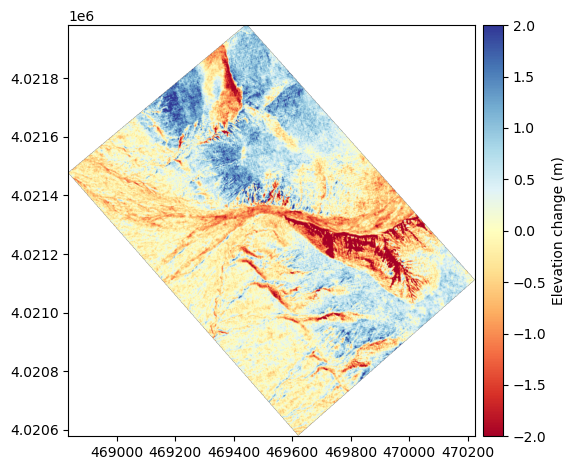

In [8]:
diff_before = reference_dem - dem_to_be_aligned_2
diff_before.plot(cmap="RdYlBu", vmin=-2, vmax=2, cbar_title="Elevation change (m)")

In [9]:
diff_before.info(stats=True)

Driver:               None 
Opened from file:     None 
Filename:             None 
Loaded?               True 
Modified since load?  True 
Grid size:            890, 901
Number of bands:      1
Data types:           float32
Coordinate system:    ['EPSG:32611']
Nodata value:         -9999.0
Pixel interpretation: Area
Pixel size:           1.5584500000000476, 1.5584500000003796
Upper left corner:    468835.5897, 4020577.52395
Lower right corner:   470222.61020000005, 4021981.6874

Statistics:
Mean                   : 0.04
Median                 : 0.06
Max                    : 5.33
Min                    : -10.08
Sum                    : 15205.16
Sum of squares         : 268250.50
90th percentile        : 0.94
LE90                   : 2.37
NMAD                   : 0.61
RMSE                   : 0.83
Standard deviation     : 0.83
Valid count            : 386779.00
Total count            : 801890.00
Percentage valid points: 48.23



Horizontal and vertical shifts can be estimated using :class:`~xdem.coreg.NuthKaab`.
The shifts are estimated then applied to the to-be-aligned elevation data:



In [10]:
nuth_kaab = xdem.coreg.NuthKaab()
aligned_dem = nuth_kaab.fit_and_apply(reference_dem, dem_to_be_aligned_2) #, inlier_mask)

The shifts are stored in the affine metadata output



In [11]:
print([nuth_kaab.meta["outputs"]["affine"][s] for s in ["shift_x", "shift_y", "shift_z"]])
print(nuth_kaab.meta["outputs"])

[np.float64(-0.35303287977979503), np.float64(-1.0426638105389285), -0.09759964966195867]
{'affine': {'shift_x': np.float64(-0.35303287977979503), 'shift_y': np.float64(-1.0426638105389285), 'shift_z': -0.09759964966195867}, 'random': {'subsample_final': np.int64(385279)}}


Then, the new difference can be plotted to validate that it improved.



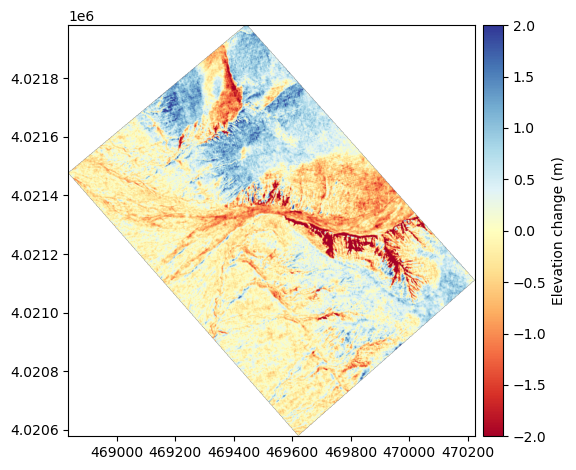

In [12]:
diff_after = reference_dem - aligned_dem

diff_after.plot(cmap="RdYlBu", vmin=-2, vmax=2, cbar_title="Elevation change (m)")


In [13]:
print(diff_after.info(stats=True))


Driver:               None 
Opened from file:     None 
Filename:             None 
Loaded?               True 
Modified since load?  True 
Grid size:            890, 901
Number of bands:      1
Data types:           float32
Coordinate system:    ['EPSG:32611']
Nodata value:         -9999.0
Pixel interpretation: None
Pixel size:           1.5584500000000476, 1.5584500000003796
Upper left corner:    468835.5897, 4020577.52395
Lower right corner:   470222.61020000005, 4021981.6874

Statistics:
Mean                   : -0.01
Median                 : 0.00
Max                    : 4.52
Min                    : -8.86
Sum                    : -3262.03
Sum of squares         : 188936.66
90th percentile        : 0.79
LE90                   : 2.07
NMAD                   : 0.52
RMSE                   : 0.70
Standard deviation     : 0.70
Valid count            : 386736.00
Total count            : 801890.00
Percentage valid points: 48.23

None


We open example files.



We compare the median and NMAD (normalized median absolute deviation) to validate numerically that there was an improvement (see `robuststats-meanstd`):



In [14]:


dif_bef_arr = diff_before.data
print('Before median: ', np.ma.median(dif_bef_arr))
print('Before NMAD: ', gu.stats.nmad(dif_bef_arr))


dif_after_arr = diff_after.data
print('After median: ', np.ma.median(dif_after_arr))
print('After NMAD: ', gu.stats.nmad(dif_after_arr))


print(f"Error before: median = {np.ma.median(dif_bef_arr)} - NMAD = {gu.stats.nmad(dif_bef_arr)} m = {np.ma.median(dif_bef_arr)-gu.stats.nmad(dif_bef_arr)}")
print(f"Error after: median = {np.ma.median(dif_after_arr)} - NMAD = {gu.stats.nmad(dif_after_arr)} m = {np.ma.median(dif_after_arr)-gu.stats.nmad(dif_after_arr)}")



''' 
nliers_before = diff_before
med_before, nmad_before = np.ma.median(inliers_before), gu.stats.nmad(inliers_before)

inliers_after = diff_after
med_after, nmad_after = np.ma.median(inliers_after), gu.stats.nmad(inliers_after)

print(f"Error before: median = {med_before:.2f} - NMAD = {nmad_before:.2f} m")
print(f"Error after: median = {med_after:.2f} - NMAD = {nmad_after:.2f} m")
'''

Before median:  0.062194824
Before NMAD:  0.6099979
After median:  0.00048828125
After NMAD:  0.52140754
Error before: median = 0.06219482421875 - NMAD = 0.6099979281425476 m = -0.5478031039237976
Error after: median = 0.00048828125 - NMAD = 0.5214075446128845 m = -0.5209192633628845


' \nnliers_before = diff_before\nmed_before, nmad_before = np.ma.median(inliers_before), gu.stats.nmad(inliers_before)\n\ninliers_after = diff_after\nmed_after, nmad_after = np.ma.median(inliers_after), gu.stats.nmad(inliers_after)\n\nprint(f"Error before: median = {med_before:.2f} - NMAD = {nmad_before:.2f} m")\nprint(f"Error after: median = {med_after:.2f} - NMAD = {nmad_after:.2f} m")\n'

In the plot above, one may notice a positive (blue) tendency toward the east.
The 1990 DEM is a mosaic, and likely has a "seam" near there.
`sphx_glr_advanced_examples_plot_blockwise_coreg.py` tackles this issue, using a nonlinear coregistration approach.



In [16]:
diff_after.save("block1_diff_after.tif", driver='GTiff')
diff_before.save("block1_diff_before.tif", driver='GTiff')